# Lab: Advanced Data Augmentation with Keras — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/03-keras-and-tensorflow/notebooks/lab-advanced-data-augmentation-with-keras.ipynb) · [Course notes](../../../courses/03-keras-and-tensorflow/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations. Bundled TensorFlow datasets use 512 training / 256 test examples; fit inputs use at most 512 examples or eight dataset batches.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader
import tensorflow as tf
tf.random.set_seed(42)
for _dataset in [tf.keras.datasets.mnist,tf.keras.datasets.fashion_mnist,tf.keras.datasets.cifar10]:
    _original_load = _dataset.load_data
    def _small_load(*args,_load=_original_load,**kwargs):
        (x,y),(xt,yt) = _load(*args,**kwargs)
        return (x[:512],y[:512]),(xt[:256],yt[:256])
    _dataset.load_data = _small_load
_keras_fit = tf.keras.Model.fit
def _small_fit(self,*args,**kwargs):
    args = list(args)
    def _limit(value):
        if isinstance(value,(np.ndarray,pd.DataFrame,pd.Series,tf.Tensor,tf.RaggedTensor)):return value[:512]
        if isinstance(value,(tuple,list)) and value and all(isinstance(x,(np.ndarray,tf.Tensor,tf.RaggedTensor)) for x in value):return type(value)(x[:512] for x in value)
        if isinstance(value,tf.data.Dataset):return value.take(8)
        return value
    for i in range(min(2,len(args))):args[i]=_limit(args[i])
    for key in ['x','y','validation_data']:
        if key in kwargs:kwargs[key]=_limit(kwargs[key])
    kwargs['epochs']=min(2,kwargs.get('epochs',2))
    data=args[0] if args else kwargs.get('x')
    if hasattr(data,'class_indices'):
        kwargs['steps_per_epoch']=min(2,len(data))
        if hasattr(kwargs.get('validation_data'),'class_indices'):
            kwargs['validation_steps']=min(2,len(kwargs['validation_data']))
    return _keras_fit(self,*args,**kwargs)
tf.keras.Model.fit = _small_fit


Matplotlib is building the font cache; this may take a moment.


<center><img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  /></center>
  


## Lab: Advanced Data Augmentation with Keras 


##### Estimated time needed:  30 minutes


You will learn to implement and experiment with various data augmentation techniques using Keras in this lab. 

#### Learning objectives 

By the end of this lab, you will: 

- Implement various data augmentation techniques using Keras 
- Implement feature-wise and sample-wise normalization on the data set. 
- Define and apply a custom augmentation function that adds random noise to images. 
- Display the augmented images to understand the effect of different augmentation techniques.  


#### Step-by-step instructions 

##### Step 1: Setup the environment 

First, you need to import the necessary libraries and load the data set as follows: 


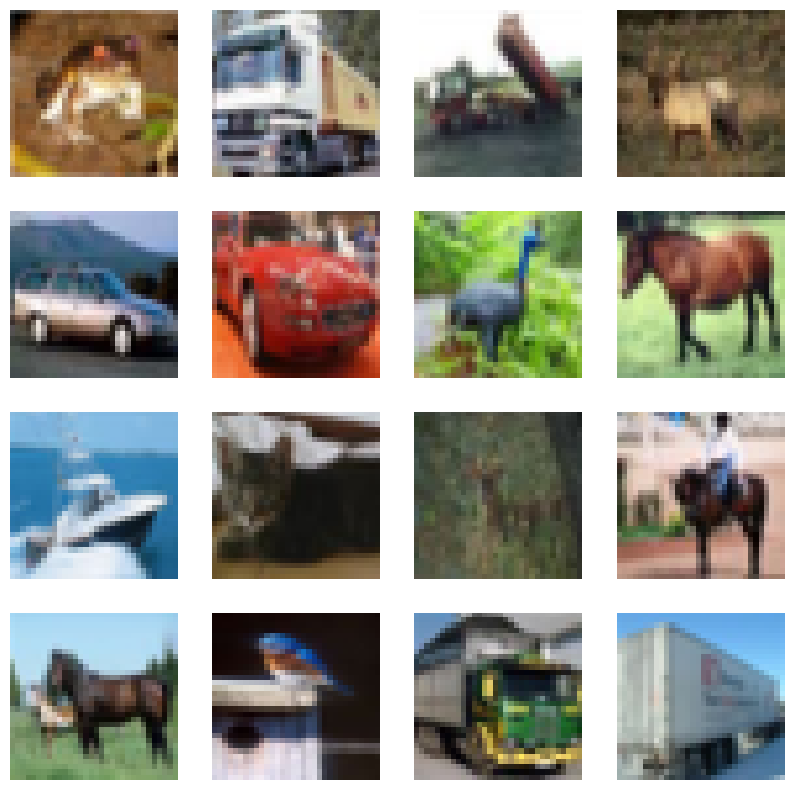

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
plt.figure(figsize=(10, 10))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_train[i])
    plt.axis('off')
plt.show()

### **Create sample.jpg for the Lab**


In [3]:
from PIL import Image, ImageDraw
image = Image.new('RGB', (224, 224), color=(255, 255, 255))
draw = ImageDraw.Draw(image)
draw.rectangle([(50, 50), (174, 174)], fill=(255, 0, 0))
image.save('sample.jpg')

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
img_path = 'sample.jpg'
img = load_img(img_path)
x = img_to_array(img)
x = np.expand_dims(x, axis=0)

In the code: 
- `!pip install tensorflow==2.16.2 matplotlib==3.9.1` installs the specified versions of `TensorFlow and Matplotlib`.  

- `tensorflow` is the main library for machine learning in Python.  

- `Model` is used to create a model with the Functional API. 

- `Input` and ‘Dense’ are types of layers that you will use in your model.  


#### Step 2: Basic data augmentation 

Apply basic augmentations such as rotation, width shift, height shift, shear, zoom, and horizontal flip using the ImageDataGenerator as follows:


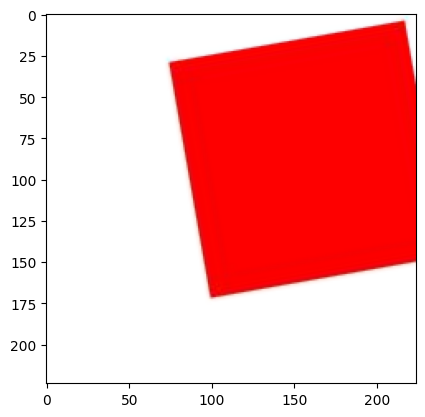

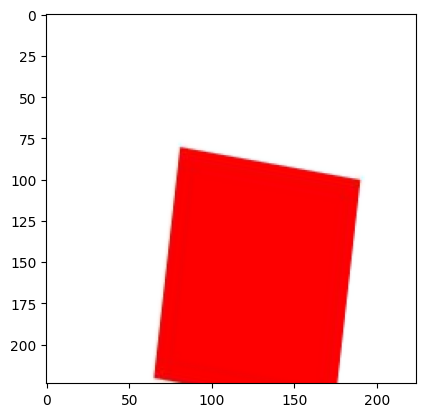

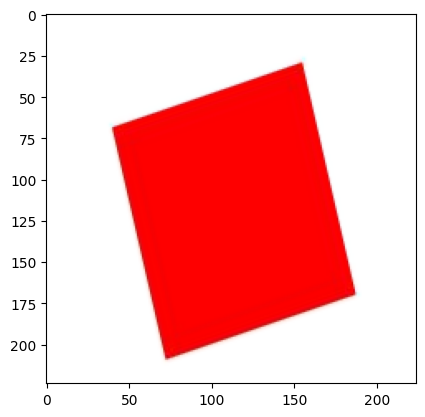

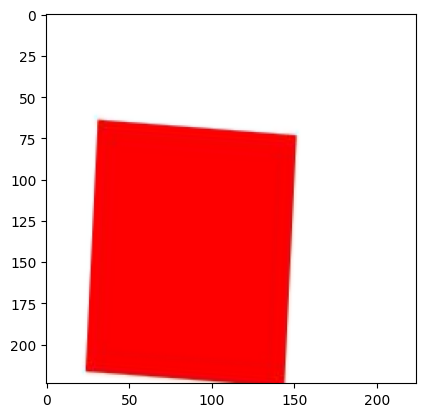

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
img_path = 'sample.jpg'
img = load_img(img_path)
x = img_to_array(img)
x = np.expand_dims(x, axis=0)
datagen = ImageDataGenerator(rotation_range=40, width_shift_range=0.2, height_shift_range=0.2, shear_range=0.2, zoom_range=0.2, horizontal_flip=True, fill_mode='nearest')
i = 0
for batch in datagen.flow(x, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(batch[0].astype('uint8'))
    i += 1
    if i % 4 == 0:
        break
plt.show()


#### Step 3: Feature-wise and sample-wise normalization 

Implement feature-wise and sample-wise normalization on the data set as follows:    


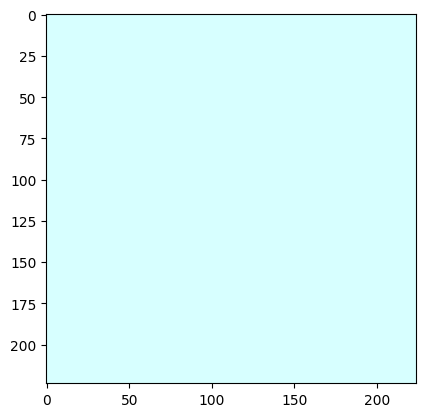

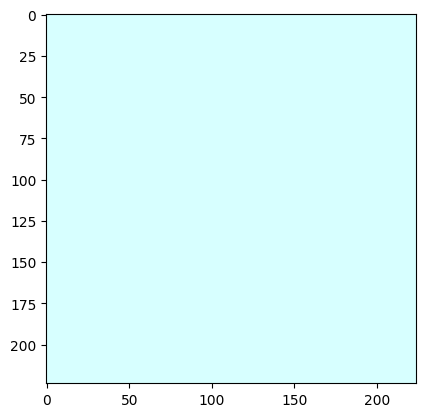

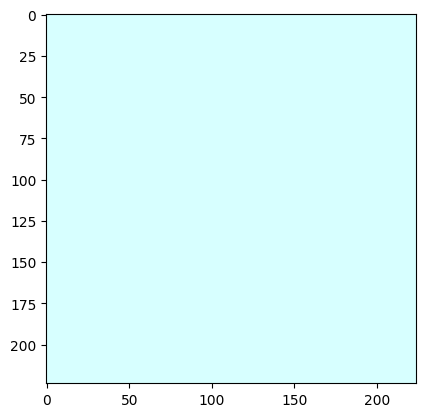

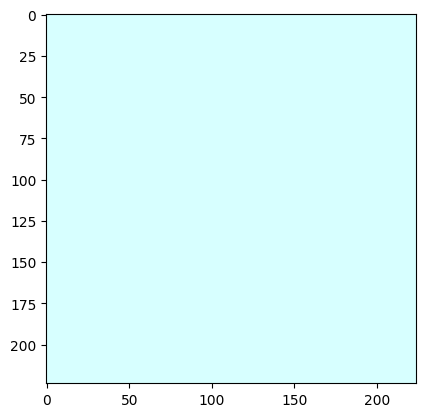

In [6]:
datagen = ImageDataGenerator(featurewise_center=True, featurewise_std_normalization=True, samplewise_center=True, samplewise_std_normalization=True)
datagen.fit(x)
i = 0
for batch in datagen.flow(x, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(batch[0].astype('uint8'))
    i += 1
    if i % 4 == 0:
        break
plt.show()



#### Step 4: Custom data augmentation function 

Next, you define and apply a custom augmentation function that adds random noise to images as follows: 


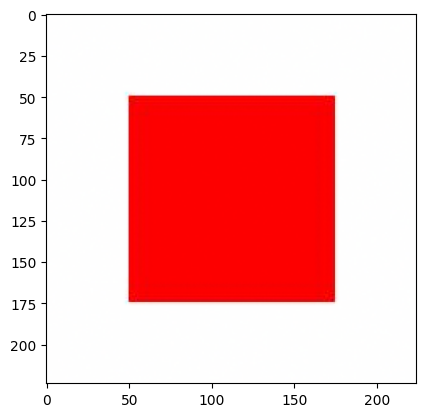

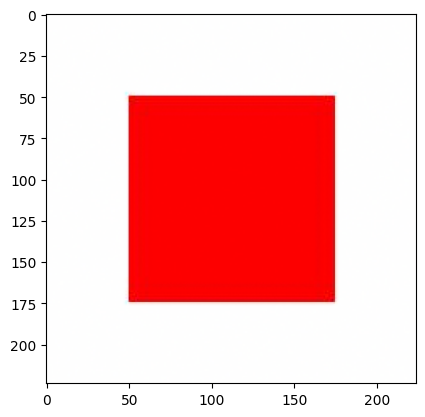

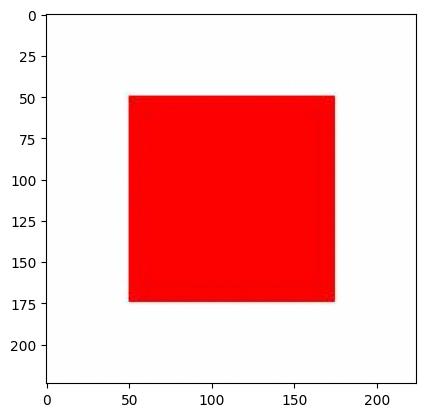

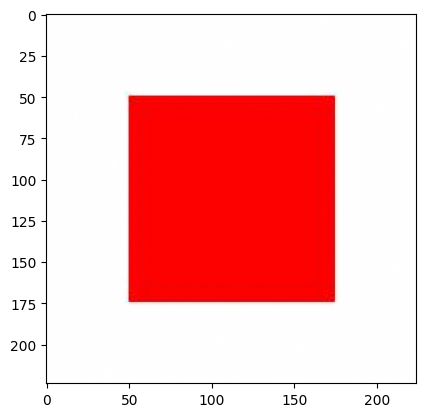

In [7]:
def add_random_noise(image):
    noise = np.random.normal(0, 0.1, image.shape)
    return image + noise
datagen = ImageDataGenerator(preprocessing_function=add_random_noise)
i = 0
for batch in datagen.flow(x, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(batch[0].astype('uint8'))
    i += 1
    if i % 4 == 0:
        break
plt.show()

#### Step 5: Visualize augmented images 

Visualize the augmented images to understand the impact of each augmentation technique. 


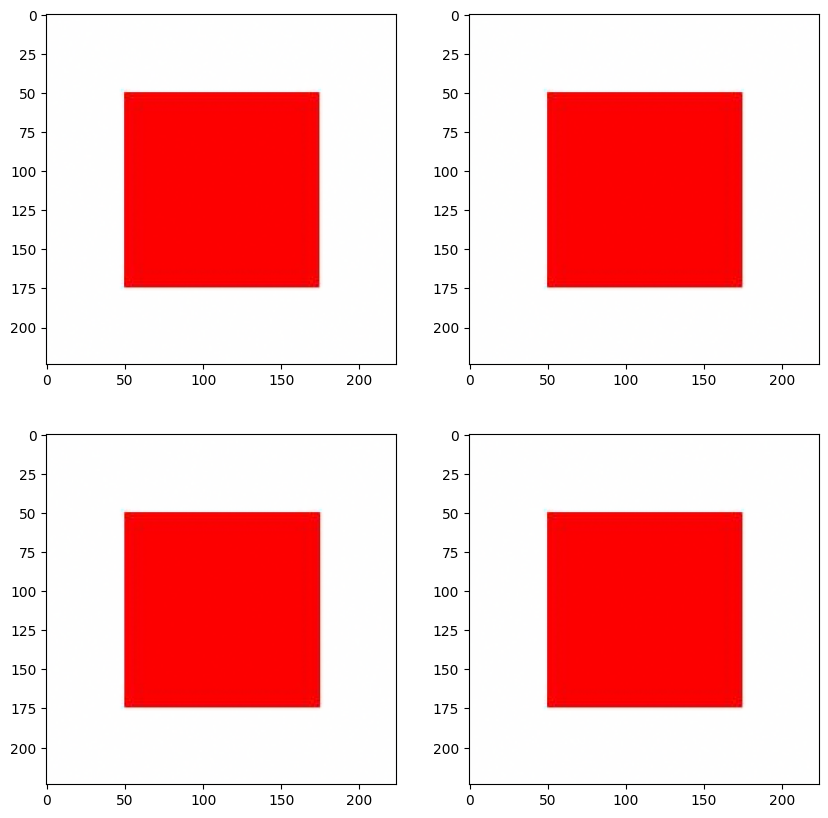

In [8]:
plt.figure(figsize=(10, 10))
for i, batch in enumerate(datagen.flow(x, batch_size=1)):
    if i >= 4:
        break
    plt.subplot(2, 2, i + 1)
    plt.imshow(batch[0].astype('uint8'))
plt.show()


This Markdown explanation will provide clarity in a Jupyter Notebook, making the code and its purpose easier to understand.


## Practice Exercises:


### Exercise 1: Apply and Visualize Different Augmentation Techniques 

  

Objective: Experiment with different augmentation techniques and visualize their effects. 


Download the `sample_images` folder containing a collection of images that will be used for this practice exercise.


In [9]:
from pathlib import Path as _LabPath
from urllib.request import urlopen as _lab_urlopen
from shutil import copyfileobj as _lab_copyfileobj

def _download_lab_asset(url, filename):
    target = _LabPath(filename)
    if not target.is_file():
        partial = target.with_name(target.name + '.part')
        try:
            with _lab_urlopen(url, timeout=60) as response, partial.open('wb') as output:
                _lab_copyfileobj(response, output)
            partial.replace(target)
        finally:
            partial.unlink(missing_ok=True)
    return target
_download_lab_asset('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/RgP3JFNtPTZA34UmG3KZaA/sample-images.zip', 'sample-images.zip')

PosixPath('sample-images.zip')

Extract the images by unzipping the folder


In [10]:
get_ipython().system('unzip sample-images.zip')

Archive:  sample-images.zip
   creating: sample_images
  inflating: sample_images/training_images1.jpg  
  inflating: sample_images/training_images2.jpg  
  inflating: sample_images/training_images3.jpg  


### Instructions: 

1. Create an instance of `ImageDataGenerator` with various augmentations such as rotation, width shift, height shift, shear, zoom, and horizontal flip. 

2. Generate and visualize augmented images. 


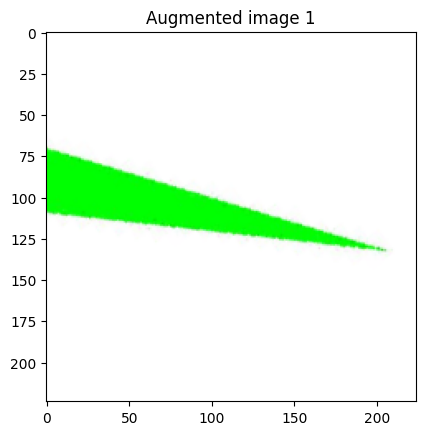

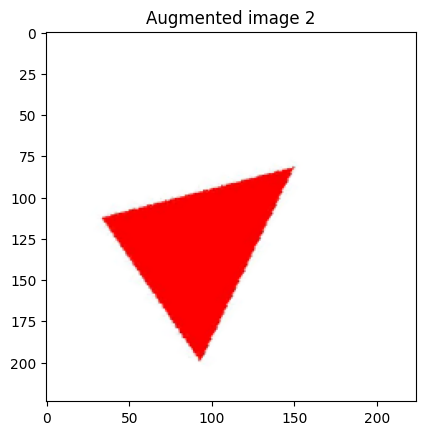

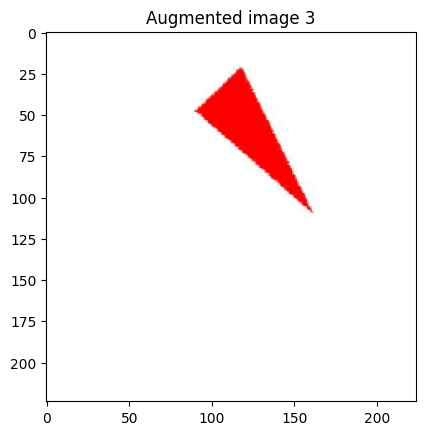

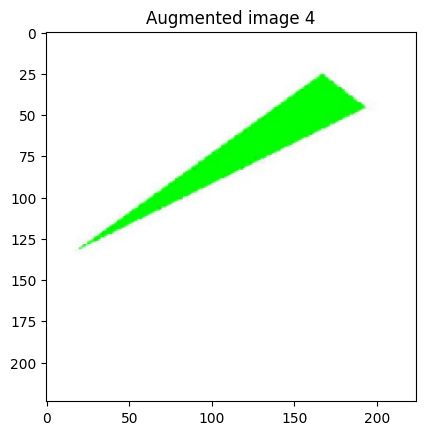

In [11]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img
image_paths = ['sample_images/training_images1.jpg', 'sample_images/training_images2.jpg', 'sample_images/training_images3.jpg']
training_images = np.stack([img_to_array(load_img(name, target_size=(224, 224))) for name in image_paths])
datagen = ImageDataGenerator(rotation_range=40, width_shift_range=0.2, height_shift_range=0.2, shear_range=0.2, zoom_range=0.2, horizontal_flip=True, fill_mode='nearest')
for index, batch in enumerate(datagen.flow(training_images, batch_size=1, seed=42)):
    plt.figure()
    plt.imshow(array_to_img(batch[0]))
    plt.title(f'Augmented image {index + 1}')
    if index == 3:
        break
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python

 

from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img  

import matplotlib.pyplot as plt  

import numpy as np  

 

# Define the augmentation parameters  

datagen = ImageDataGenerator(  

    rotation_range=40,  

    width_shift_range=0.2,  

    height_shift_range=0.2,  

    shear_range=0.2,  

    zoom_range=0.2,  

    horizontal_flip=True,  

    fill_mode='nearest'  

)  

 

# Load and preprocess the dataset  

image_paths = [  

    'sample_images/training_images1.jpg',  

    'sample_images/training_images2.jpg',  

    'sample_images/training_images3.jpg'  

]  

 

training_images = []  

for image_path in image_paths:  

    img = load_img(image_path, target_size=(224, 224))  

    img_array = img_to_array(img)  

    training_images.append(img_array)  

training_images = np.array(training_images)  

 

# Generate and visualize augmented images  

i = 0  

for batch in datagen.flow(training_images, batch_size=1):  

    plt.figure(i)  

    imgplot = plt.imshow(array_to_img(batch[0]))  

    plt.title(f'Augmented Image {i + 1}')  

    i += 1  

    if i % 4 == 0:  

        break  

plt.show()  

 ```   

</details>


### Exercise 2: Implement Feature-wise and Sample-wise Normalization
 
Objective: Apply feature-wise and sample-wise normalization to the dataset.
 
Instructions:
1. Create an instance of `ImageDataGenerator` with feature-wise and sample-wise normalization.
2. Fit the `ImageDataGenerator` to the data set and visualize the normalized images.


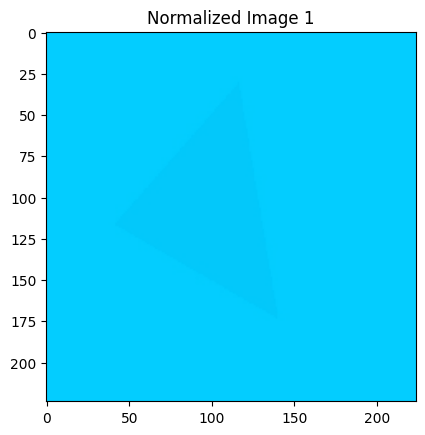

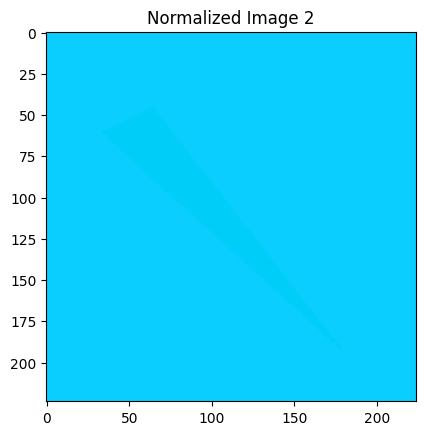

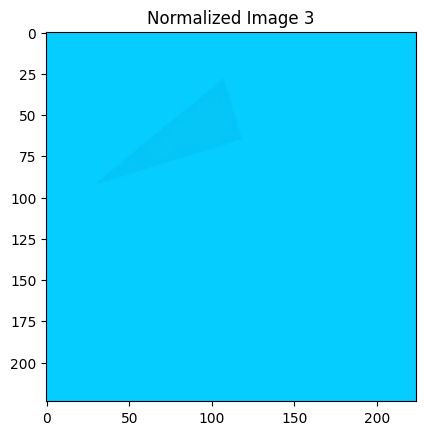

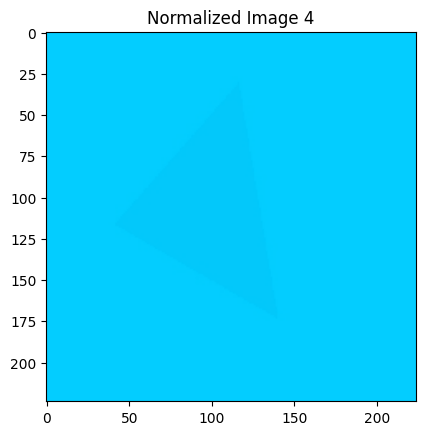

In [12]:
datagen = ImageDataGenerator(featurewise_center=True, featurewise_std_normalization=True, samplewise_center=True, samplewise_std_normalization=True)
datagen.fit(training_images)
i = 0
for batch in datagen.flow(training_images, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(array_to_img(batch[0]))
    plt.title(f'Normalized Image {i + 1}')
    i += 1
    if i % 4 == 0:
        break
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
 

# Create an instance of ImageDataGenerator with normalization options  

datagen = ImageDataGenerator(  

    featurewise_center=True,  

    featurewise_std_normalization=True,  

    samplewise_center=True,  

    samplewise_std_normalization=True  

)  

 

# Fit the ImageDataGenerator to the dataset  

datagen.fit(training_images)  

 

# Generate and visualize normalized images  

i = 0  

for batch in datagen.flow(training_images, batch_size=1):  

    plt.figure(i)  

    imgplot = plt.imshow(array_to_img(batch[0]))  

    plt.title(f'Normalized Image {i + 1}')  

    i += 1  

    if i % 4 == 0:  

        break  

plt.show()  

 

 ```   

</details>

  


### Exercise 3: Create and Apply a Custom Data Augmentation Function
 
Objective: Define a custom data augmentation function that adds random noise to images and apply it.
 
Instructions:
1. Define a function that adds random noise to an image.
2. Create an instance of `ImageDataGenerator` with the custom augmentation function.
3. Generate and visualize augmented images.


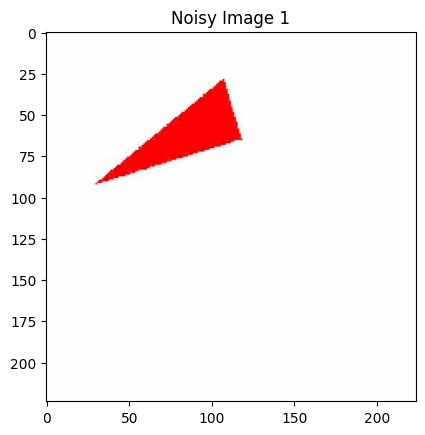

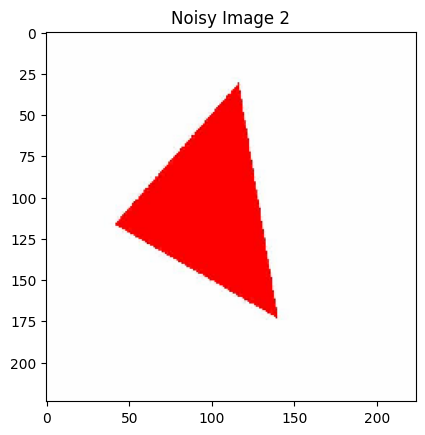

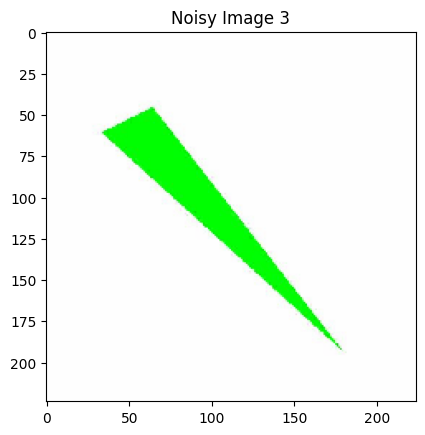

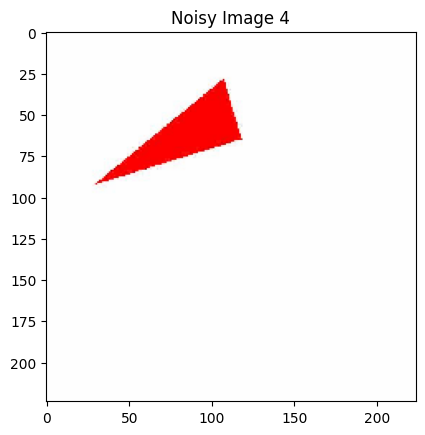

In [13]:
def add_random_noise(image):
    noise = np.random.normal(0, 0.1, image.shape)
    return image + noise
datagen = ImageDataGenerator(preprocessing_function=add_random_noise)
i = 0
for batch in datagen.flow(training_images, batch_size=1):
    plt.figure(i)
    imgplot = plt.imshow(array_to_img(batch[0]))
    plt.title(f'Noisy Image {i + 1}')
    i += 1
    if i % 4 == 0:
        break
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python

 

# Define a custom augmentation function to add random noise  

def add_random_noise(image):  

    noise = np.random.normal(0, 0.1, image.shape)  

    return image + noise  

 

# Create an instance of ImageDataGenerator with custom augmentation  

datagen = ImageDataGenerator(preprocessing_function=add_random_noise)  

 

# Generate and visualize augmented images  

i = 0  

for batch in datagen.flow(training_images, batch_size=1):  

    plt.figure(i)  

    imgplot = plt.imshow(array_to_img(batch[0]))  

    plt.title(f'Noisy Image {i + 1}')  

    i += 1  

    if i % 4 == 0:  

        break  

plt.show()  

 ```   

</details>


## **Conclusion**
Congratulations! You have successfully implemented and experimented with various data augmentation techniques using Keras. This lab exercise demonstrated how to use Keras to enhance your datasets through augmentation and normalization techniques. 


## Authors


Skillup 


Copyright © IBM Corporation. All rights reserved.
